# 날씨 기반 따릉이 수요 예측모델 개발 및 시뮬레이션

- 목표 : 기상 조건과 과거 대여량으로 **다음 날 서울 공공자전거(따릉이) 일별 대여건수**를 예측하고, 날씨 시나리오별 수요 변화를 확인한다.
- 데이터 : 서울 열린데이터광장 `공공자전거 일별 대여건수`, 기상청 기상자료개방포털 서울(108) ASOS 일자료
- 모델 : LSTM(최근 14일 시퀀스) + 대상일 기상·달력 변수를 합친 구조
- 폴더 구조 : `data/bike/`(CSV·XLSX), `data/weather/`(CSV)에 원본 파일을 넣고 위에서부터 실행한다.

> Colab에서 실행할 때는 첫 셀에서 `!pip install holidays`, `!apt-get -qq install fonts-nanum` 실행 후 런타임을 다시 시작한다.

In [1]:
import glob, json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
import holidays
warnings.filterwarnings('ignore')

from pathlib import Path

def find_data_dir():
    # 노트북 실행 위치(및 상위 폴더) 근처에서 data/bike 폴더를 찾는다
    here = Path.cwd()
    for base in [here] + list(here.parents)[:3]:
        for cand in [base / 'data'] + list(base.glob('*/data')) + list(base.glob('*/*/data')):
            if (cand / 'bike').is_dir():
                return str(cand)
    return 'data'

DATA_DIR, FIG_DIR = find_data_dir(), 'figs'
print('현재 위치 :', os.getcwd())
print('데이터 폴더 :', os.path.abspath(DATA_DIR))
SEED, WINDOW = 42, 14            # 입력 시퀀스 길이(일)
os.makedirs(FIG_DIR, exist_ok=True)

# 그래프 한글 폰트 : 폰트 파일 경로를 직접 등록 (설치 직후 캐시 문제 방지)
FONT_FILES = ['C:/Windows/Fonts/NanumGothic.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf', 'C:/Windows/Fonts/malgun.ttf',
              '/System/Library/Fonts/AppleSDGothicNeo.ttc', '/Library/Fonts/NanumGothic.ttf']
for p in FONT_FILES:
    if os.path.exists(p):
        font_manager.fontManager.addfont(p)
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=p).get_name()
        break
else:
    print('한글 폰트를 찾지 못했습니다. 그래프 글자가 깨질 수 있음')
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid', {'font.family': plt.rcParams['font.family']})
GREEN, ORANGE = '#1E4D3B', '#E8743B'

def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=160, bbox_inches='tight')

def save_table(df, name, max_rows=10, fs=10):
    # 표를 이미지로 저장 (보고서 캡처용)
    d = df.head(max_rows)
    fig, ax = plt.subplots(figsize=(min(1.5 + 1.35 * len(d.columns), 15), 0.42 * (len(d) + 2)))
    ax.axis('off')
    t = ax.table(cellText=d.values, colLabels=list(d.columns), loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(fs); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        if r == 0:
            cell.set_facecolor(GREEN); cell.set_text_props(color='white', weight='bold')
    save_fig(name); plt.show()

현재 위치 : DL
데이터 폴더 : DL/data


## 1. 데이터 수집

In [2]:
def read_csv_any(path):
    for enc in ('utf-8-sig', 'cp949', 'euc-kr'):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f'인코딩 확인 필요: {path}')

def read_table(path):
    if path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path)
    return read_csv_any(path)

def list_files(folder):
    return sorted(f for ext in ('csv', 'xlsx', 'xls') for f in glob.glob(f'{DATA_DIR}/{folder}/*.{ext}'))

def find_col(df, *keys):
    # 컬럼명에 keys가 모두 들어간 첫 컬럼
    for c in df.columns:
        if all(k in str(c) for k in keys):
            return c
    raise KeyError(f'{keys} 컬럼 없음. 현재 컬럼: {list(df.columns)}')

def to_date(s):
    return pd.to_datetime(s.astype(str).str.replace(r'\D', '', regex=True).str[:8], format='%Y%m%d', errors='coerce')

# (1) 따릉이 : 날짜별 이용건수 합계
bike_files = list_files('bike')
if not bike_files:
    raise FileNotFoundError(f"따릉이 파일이 없습니다. '{os.path.abspath(DATA_DIR)}/bike' 안에 CSV를 넣거나, 이 노트북과 같은 폴더에 data/bike, data/weather 폴더를 두세요.")
bike_raw = pd.concat([read_table(f) for f in bike_files], ignore_index=True).drop_duplicates()
try:
    c_date = find_col(bike_raw, '일자')
except KeyError:
    c_date = find_col(bike_raw, '일시')        # 2022년 파일처럼 컬럼명이 다른 경우
c_cnt = find_col(bike_raw, '건수')
bike_raw['date'] = to_date(bike_raw[c_date])
bike_raw[c_cnt] = pd.to_numeric(bike_raw[c_cnt].astype(str).str.replace(',', ''), errors='coerce')
bike = bike_raw.dropna(subset=['date']).groupby('date')[c_cnt].sum().rename('rides')
print(f'따릉이 파일 {len(bike_files)}개, 원본 {len(bike_raw):,}행 -> 일별 {len(bike):,}일 ({bike.index.min().date()} ~ {bike.index.max().date()})')

# (2) 기상 : 서울 ASOS 일자료
w_files = list_files('weather')
if not w_files:
    raise FileNotFoundError(f"기상 파일이 없습니다. '{os.path.abspath(DATA_DIR)}/weather' 안에 기상청 CSV를 넣어 주세요.")
w_raw = pd.concat([read_table(f) for f in w_files], ignore_index=True)
w_raw['date'] = to_date(w_raw[find_col(w_raw, '일시')])
cols = {'temp_mean': find_col(w_raw, '평균기온'), 'temp_min': find_col(w_raw, '최저기온'), 'temp_max': find_col(w_raw, '최고기온'),
        'rain': find_col(w_raw, '일강수량'), 'wind': find_col(w_raw, '평균', '풍속'), 'humid': find_col(w_raw, '평균', '습도')}
weather = w_raw.dropna(subset=['date']).drop_duplicates('date').set_index('date')[list(cols.values())]
weather.columns = list(cols.keys())
print(f'기상 데이터 {len(weather):,}일 ({weather.index.min().date()} ~ {weather.index.max().date()})')

# (3) 날짜 기준 병합
df = bike.to_frame().join(weather, how='inner').sort_index()
full = pd.date_range(df.index.min(), df.index.max())
print('병합 후', len(df), '일 / 빠진 날짜', len(full) - len(df), '일')
df = df.reindex(full); df.index.name = 'date'
df.head()

따릉이 파일 5개, 원본 912행 -> 일별 912일 (2024-01-01 ~ 2026-06-30)
기상 데이터 912일 (2024-01-01 ~ 2026-06-30)
병합 후 912 일 / 빠진 날짜 0 일


,rides,temp_mean,temp_min,temp_max,rain,wind,humid
date,,,,,,,
2024-01-01,46628,3.3,-0.3,7.3,0.0,1.7,83.4
2024-01-02,86401,2.9,2.2,4.3,0.0,1.6,72.6
2024-01-03,71808,1.8,-1.1,4.0,0.6,1.6,80.4
2024-01-04,90108,1.4,-3.3,4.7,NaN,1.9,74.3
2024-01-05,94927,5.0,1.4,9.1,0.0,2.3,77.1


findfont: Failed to find font weight bold for NanumGothic, now using 400.


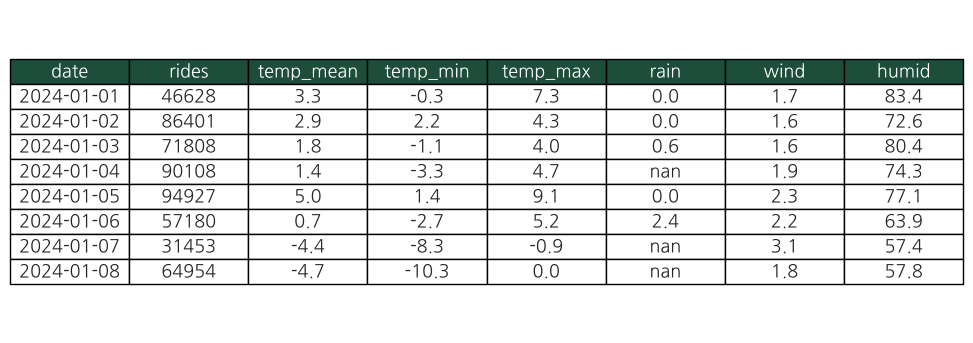

In [3]:
head = df.head(8).reset_index()
head['date'] = head['date'].dt.strftime('%Y-%m-%d')
save_table(head.round(1), 'data', fs=13)

## 2. 탐색적 데이터 분석(EDA)

findfont: Failed to find font weight bold for NanumGothic, now using 400.


중복 날짜 : 0 건  (강수량 결측은 비가 오지 않은 날의 빈칸)


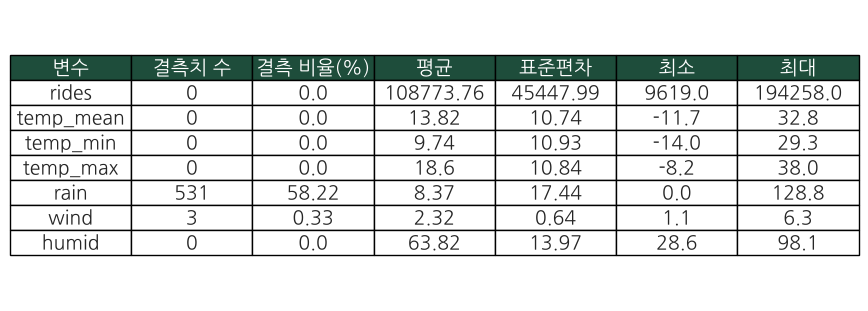

,변수,결측치 수,결측 비율(%),평균,표준편차,최소,최대
0,rides,0,0.00,108773.76,45447.99,9619.0,194258.0
1,temp_mean,0,0.00,13.82,10.74,-11.7,32.8
2,temp_min,0,0.00,9.74,10.93,-14.0,29.3
3,temp_max,0,0.00,18.60,10.84,-8.2,38.0
4,rain,531,58.22,8.37,17.44,0.0,128.8
5,wind,3,0.33,2.32,0.64,1.1,6.3
6,humid,0,0.00,63.82,13.97,28.6,98.1


In [4]:
# 결측치/중복 통계
stat = pd.DataFrame({'결측치 수': df.isna().sum(), '결측 비율(%)': (df.isna().mean() * 100).round(2),
                     '평균': df.mean().round(2), '표준편차': df.std().round(2), '최소': df.min().round(2), '최대': df.max().round(2)})
print('중복 날짜 :', df.index.duplicated().sum(), '건  (강수량 결측은 비가 오지 않은 날의 빈칸)')
stat = stat.reset_index().rename(columns={'index': '변수'})
save_table(stat, 'eda1', fs=14)
stat

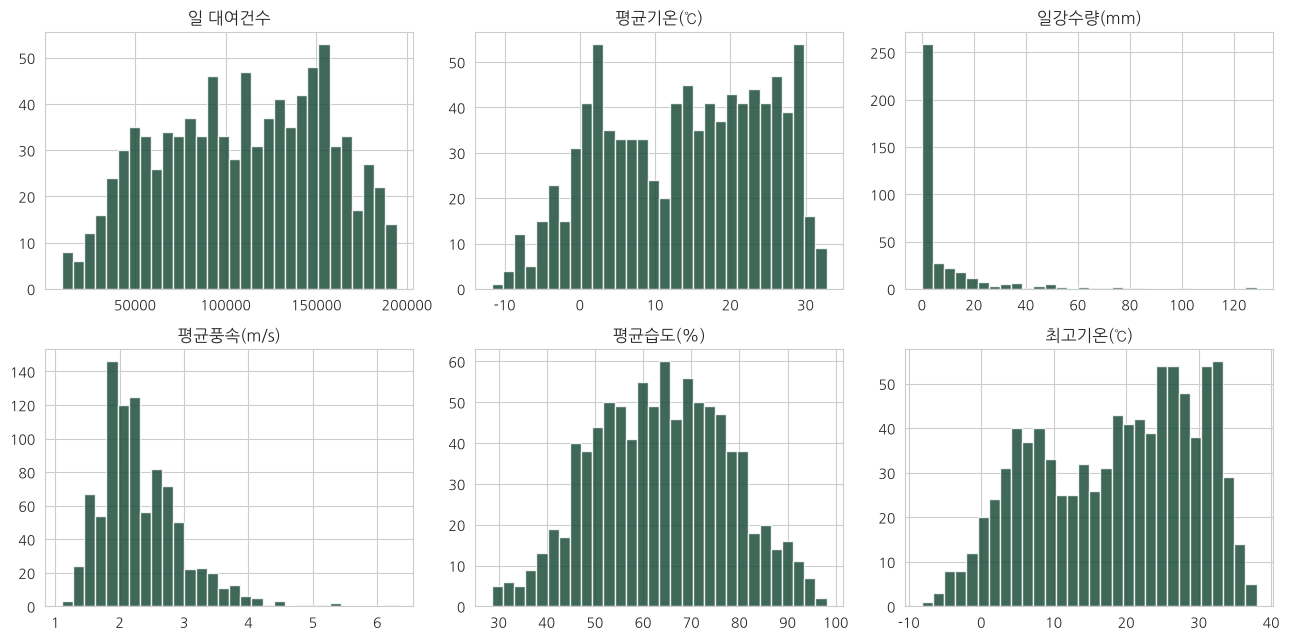

강수량 왜도 : 3.57 -> 0이 많고 오른쪽으로 치우쳐 log1p 변환 적용 예정


In [5]:
# 변수별 분포
label = {'rides': '일 대여건수', 'temp_mean': '평균기온(℃)', 'rain': '일강수량(mm)', 'wind': '평균풍속(m/s)', 'humid': '평균습도(%)', 'temp_max': '최고기온(℃)'}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (c, t) in zip(axes.ravel(), label.items()):
    ax.hist(df[c].dropna(), bins=30, color=GREEN, alpha=.85); ax.set_title(t)
plt.tight_layout(); save_fig('eda2'); plt.show()
print('강수량 왜도 :', round(df['rain'].skew(), 2), '-> 0이 많고 오른쪽으로 치우쳐 log1p 변환 적용 예정')

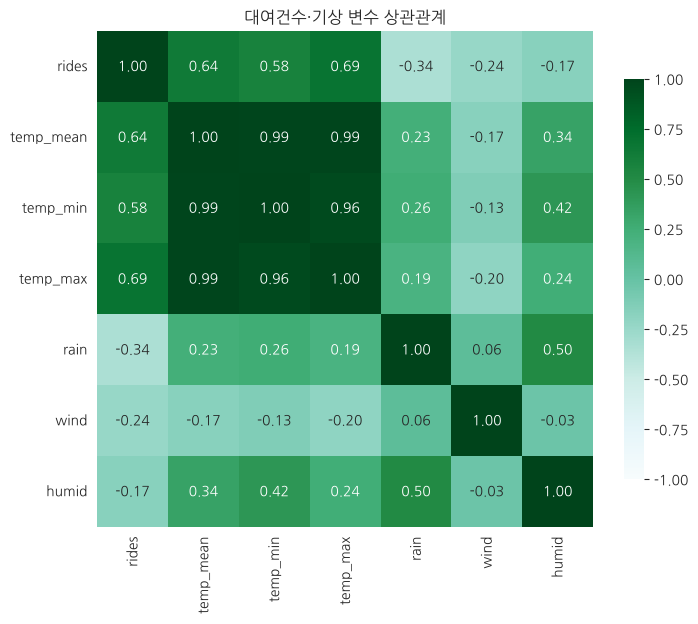

In [6]:
# 상관관계 히트맵
plt.figure(figsize=(8, 6.5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='BuGn', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .8})
plt.title('대여건수·기상 변수 상관관계')
save_fig('corr'); plt.show()

## 3. 데이터 전처리

- 결측: 강수량은 비가 없는 날이 빈칸이므로 0, 나머지는 선형보간(최대 3일)
- 강수량은 `log1p` 변환, 요일/월은 sin·cos로 순환 표현, 주말·공휴일은 `offday`로 표시
- 학습 / 검증 / 테스트는 **시간 순서대로** 70 / 15 / 15 로 분리 (표준화 기준은 학습 구간만 사용)

In [7]:
df['rain'] = df['rain'].fillna(0)
df = df.interpolate(limit=3).dropna()

# 날짜가 3일 넘게 끊긴 곳이 있으면 시퀀스가 이어지지 않으므로, 가장 긴 연속 구간만 사용
seg = (df.index.to_series().diff().dt.days > 1).cumsum()
if seg.nunique() > 1:
    print('연속되지 않는 구간 발견 :')
    print(df.groupby(seg.values).apply(lambda g: f'{g.index[0].date()} ~ {g.index[-1].date()} ({len(g)}일)').to_string())
    df = df[seg.values == seg.value_counts().idxmax()]
print('전처리 후', len(df), '일', f'({df.index.min().date()} ~ {df.index.max().date()})')

KR = holidays.country_holidays('KR', years=range(2017, 2029))
FEATURES = ['temp_mean', 'temp_max', 'temp_min', 'rain_log', 'wind', 'humid', 'offday', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']

def make_features(raw):
    # raw : index=date, 컬럼 temp_mean/temp_max/temp_min/rain/wind/humid
    f = pd.DataFrame(index=raw.index)
    for c in ['temp_mean', 'temp_max', 'temp_min', 'wind', 'humid']:
        f[c] = raw[c]
    f['rain_log'] = np.log1p(raw['rain'])
    f['offday'] = [int(d.weekday() >= 5 or d.date() in KR) for d in raw.index]
    f['dow_sin'] = np.sin(2 * np.pi * raw.index.dayofweek / 7)
    f['dow_cos'] = np.cos(2 * np.pi * raw.index.dayofweek / 7)
    f['month_sin'] = np.sin(2 * np.pi * (raw.index.month - 1) / 12)
    f['month_cos'] = np.cos(2 * np.pi * (raw.index.month - 1) / 12)
    return f[FEATURES]

feat = make_features(df)
rides = df['rides'].values.astype('float64')
N = len(df)
n_win = N - WINDOW                              # 만들 수 있는 (시퀀스, 정답) 개수
n_tr, n_va = int(n_win * .70), int(n_win * .85)  # 윈도우 기준 분할 지점
dates = df.index[WINDOW:]

# 표준화 : 학습 구간에 들어가는 행만 사용
fit_rows = slice(0, n_tr + WINDOW)
x_mean, x_std = feat.iloc[fit_rows].mean(), feat.iloc[fit_rows].std().replace(0, 1)
y_mean, y_std = rides[fit_rows].mean(), rides[fit_rows].std()
feat_s = ((feat - x_mean) / x_std).values
rides_s = (rides - y_mean) / y_std

seq_all = np.column_stack([rides_s, feat_s])     # 하루치 입력 = [전날까지의 대여량, 기상·달력 변수]
X_seq = np.stack([seq_all[i - WINDOW:i] for i in range(WINDOW, N)])
X_e = feat_s[WINDOW:]                            # 예측 대상일의 기상·달력 변수
y = rides_s[WINDOW:]
sp = {'train': slice(0, n_tr), 'val': slice(n_tr, n_va), 'test': slice(n_va, n_win)}
for k, s_ in sp.items():
    print(f'{k:5s} : {dates[s_][0].date()} ~ {dates[s_][-1].date()}  ({len(y[s_])}개)  입력 {X_seq[s_].shape}')

전처리 후 912 일 (2024-01-01 ~ 2026-06-30)
train : 2024-01-15 ~ 2025-10-03  (628개)  입력 (628, 14, 12)
val   : 2025-10-04 ~ 2026-02-15  (135개)  입력 (135, 14, 12)
test  : 2026-02-16 ~ 2026-06-30  (135개)  입력 (135, 14, 12)


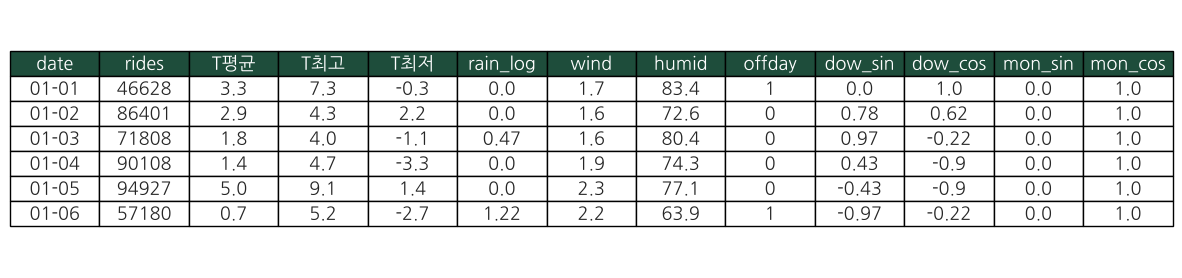

In [8]:
sample = feat.copy(); sample.insert(0, 'rides', df['rides'])
tbl = sample.head(6).round(2).reset_index(); tbl['date'] = tbl['date'].dt.strftime('%m-%d')
tbl.columns = ['date', 'rides', 'T평균', 'T최고', 'T최저', 'rain_log', 'wind', 'humid', 'offday', 'dow_sin', 'dow_cos', 'mon_sin', 'mon_cos']
save_table(tbl, 'prep', fs=13)

## 4. 모델 정의 및 컴파일

입력이 두 개인 LSTM 모델이다.
1. 최근 14일 시퀀스(대여량 + 기상·달력) → LSTM 2층으로 최근 추세를 요약
2. 예측 대상일의 기상·달력 변수 → Dense로 따로 처리 (시나리오 시뮬레이션 때 이 입력만 바꿔서 넣는다)
3. 두 결과를 합쳐서 Dense를 거쳐 다음 날 대여량 1개를 출력

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

n_in, n_e = X_seq.shape[2], X_e.shape[1]
inp_seq = keras.Input(shape=(WINDOW, n_in), name='seq')
inp_e = keras.Input(shape=(n_e,), name='target_day')
h = layers.LSTM(64, return_sequences=True, name='lstm_1')(inp_seq)
h = layers.Dropout(0.2)(h)
h = layers.LSTM(32, name='lstm_2')(h)
e = layers.Dense(16, activation='relu', name='exog_dense')(inp_e)
z = layers.Concatenate()([h, e])
z = layers.Dense(32, activation='relu', name='dense_mix')(z)
out = layers.Dense(1, name='out')(z)
model = keras.Model([inp_seq, inp_e], out, name='ddareungi_lstm')
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
model.summary()

I0000 00:00:1794186397.060401      93 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794186408.325872      93 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794186414.267761      93 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "ddareungi_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ seq (InputLayer)    │ (None, 14, 12)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 14, 64)    │     19,712 │ seq[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 14, 64)    │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_day          │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 32)        │     12,416 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exog_dense (Dense)  │ (None, 16)        │        192 │ target_day[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48)        │          0 │ lstm_2[0][0],     │
│ (Concatenate)       │                   │            │ exog_dense[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_mix (Dense)   │ (None, 32)        │      1,568 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ out (Dense)         │ (None, 1)         │         33 │ dense_mix[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,921 (132.50 KB)

 Trainable params: 33,921 (132.50 KB)

 Non-trainable params: 0 (0.00 B)

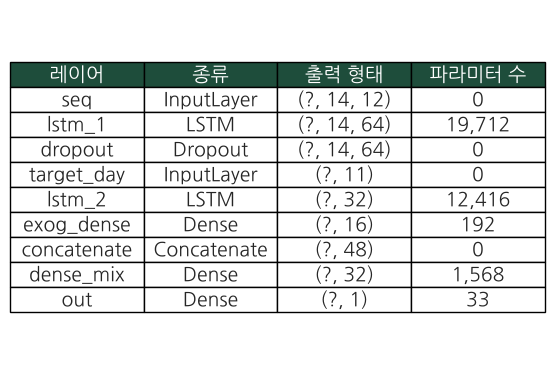

In [10]:
info = pd.DataFrame([(l.name, type(l).__name__, str(l.output.shape).replace('None', '?') if hasattr(l, 'output') else '', f'{l.count_params():,}')
                     for l in model.layers], columns=['레이어', '종류', '출력 형태', '파라미터 수'])
save_table(info, 'model', max_rows=12, fs=14)

## 5. 모델 학습

In [11]:
cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=7, min_lr=1e-5)]
hist = model.fit([X_seq[sp['train']], X_e[sp['train']]], y[sp['train']],
                 validation_data=([X_seq[sp['val']], X_e[sp['val']]], y[sp['val']]),
                 epochs=200, batch_size=32, callbacks=cb, verbose=2)
print('학습한 에폭 수 :', len(hist.history['loss']))

Epoch 1/200


20/20 - 3s - 142ms/step - loss: 0.7521 - mae: 0.7189 - val_loss: 0.3536 - val_mae: 0.4479 - learning_rate: 0.0010


Epoch 2/200


20/20 - 1s - 36ms/step - loss: 0.3917 - mae: 0.4890 - val_loss: 0.2330 - val_mae: 0.3570 - learning_rate: 0.0010


Epoch 3/200


20/20 - 0s - 15ms/step - loss: 0.2642 - mae: 0.3918 - val_loss: 0.2533 - val_mae: 0.3930 - learning_rate: 0.0010


... (69 outputs left out)

20/20 - 0s - 16ms/step - loss: 0.0331 - mae: 0.1311 - val_loss: 0.1293 - val_mae: 0.2578 - learning_rate: 5.0000e-04


Epoch 39/200


20/20 - 0s - 15ms/step - loss: 0.0306 - mae: 0.1296 - val_loss: 0.1266 - val_mae: 0.2548 - learning_rate: 2.5000e-04


학습한 에폭 수 : 39


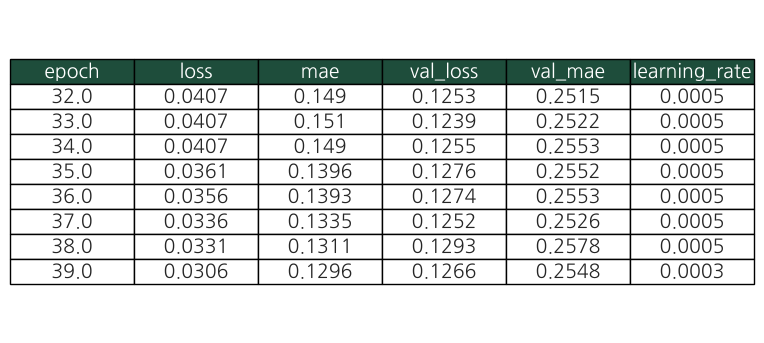

In [12]:
h = pd.DataFrame(hist.history); h.insert(0, 'epoch', np.arange(1, len(h) + 1))
save_table(h.tail(8).round(4), 'train', fs=14)

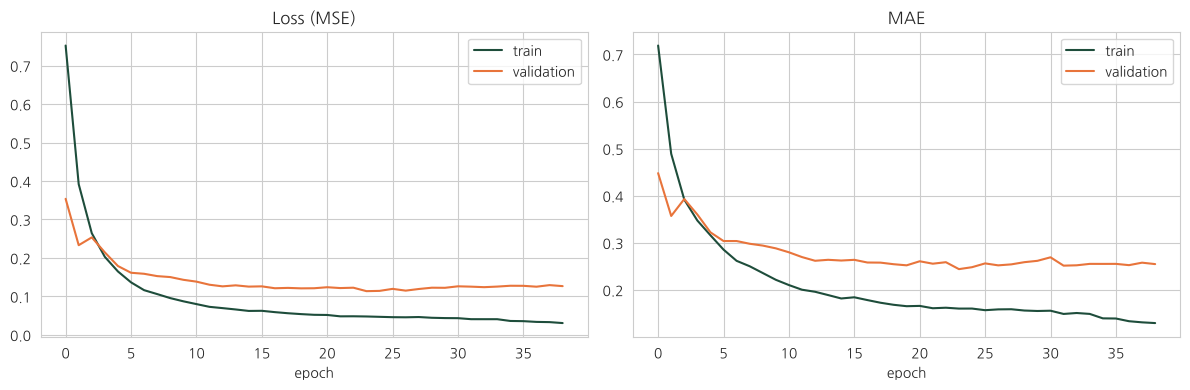

In [13]:
# 학습 과정 시각화
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h['loss'], label='train', color=GREEN); ax[0].plot(h['val_loss'], label='validation', color=ORANGE)
ax[0].set_title('Loss (MSE)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['mae'], label='train', color=GREEN); ax[1].plot(h['val_mae'], label='validation', color=ORANGE)
ax[1].set_title('MAE'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); save_fig('curve'); plt.show()

## 6. 모델 예측 및 평가

findfont: Failed to find font weight bold for NanumGothic, now using 400.


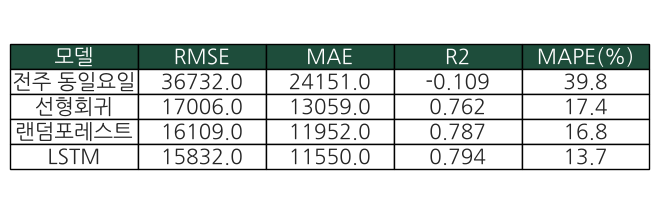

,모델,RMSE,MAE,R2,MAPE(%)
0,전주 동일요일,36732.0,24151.0,-0.109,39.8
1,선형회귀,17006.0,13059.0,0.762,17.4
2,랜덤포레스트,16109.0,11952.0,0.787,16.8
3,LSTM,15832.0,11550.0,0.794,13.7


In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

te = sp['test']
inv = lambda a: a * y_std + y_mean                        # 표준화 해제
y_true = inv(y[te])
p_lstm = inv(model.predict([X_seq[te], X_e[te]], verbose=0).ravel())

# 비교 모델 : (1) 전주 같은 요일 값 (2) 선형회귀 (3) 랜덤포레스트
lag1, lag7 = rides_s[WINDOW - 1:N - 1], rides_s[WINDOW - 7:N - 7]
X_tab = np.column_stack([X_e, lag1, lag7])
p_naive = inv(lag7[te])
lr = LinearRegression().fit(X_tab[sp['train']], y[sp['train']])
rf = RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X_tab[sp['train']], y[sp['train']])
p_lr, p_rf = inv(lr.predict(X_tab[te])), inv(rf.predict(X_tab[te]))

def score(t, p):
    return {'RMSE': np.sqrt(mean_squared_error(t, p)), 'MAE': mean_absolute_error(t, p), 'R2': r2_score(t, p), 'MAPE(%)': np.mean(np.abs(t - p) / t) * 100}
res = pd.DataFrame({'전주 동일요일': score(y_true, p_naive), '선형회귀': score(y_true, p_lr),
                    '랜덤포레스트': score(y_true, p_rf), 'LSTM': score(y_true, p_lstm)}).T
res = res.round({'RMSE': 0, 'MAE': 0, 'R2': 3, 'MAPE(%)': 1}).reset_index().rename(columns={'index': '모델'})
save_table(res, 'metrics', fs=15)
res

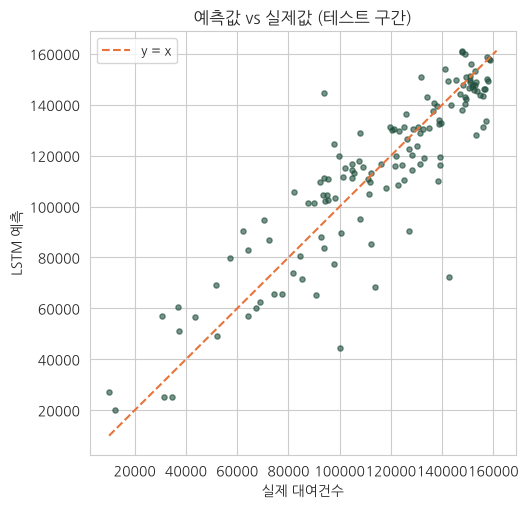

In [15]:
# 예측값 vs 실제값
lim = [min(y_true.min(), p_lstm.min()), max(y_true.max(), p_lstm.max())]
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_true, p_lstm, s=14, alpha=.6, color=GREEN)
plt.plot(lim, lim, '--', color=ORANGE, label='y = x')
plt.xlabel('실제 대여건수'); plt.ylabel('LSTM 예측'); plt.title('예측값 vs 실제값 (테스트 구간)'); plt.legend()
save_fig('pred'); plt.show()

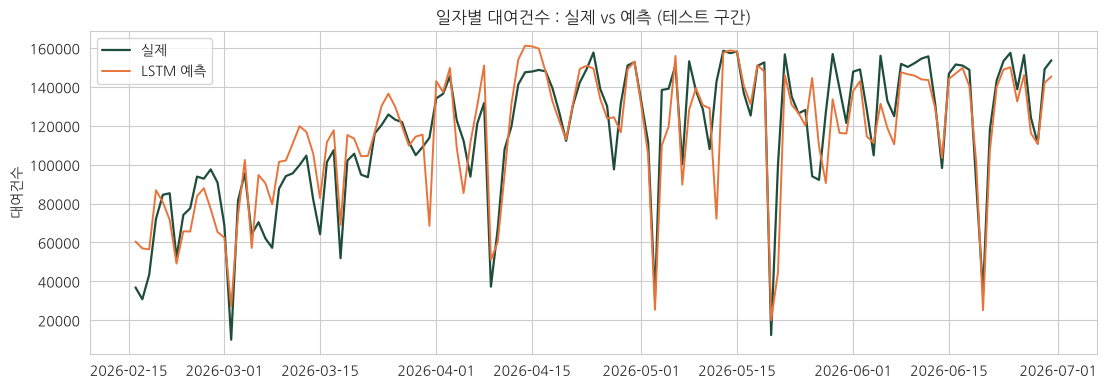

오차가 큰 날 Top 5
                  실제        예측  rain  temp_mean
date                                           
2026-05-12  142689.0   72199.0  18.1       19.1
2026-05-21  100062.0   44610.0  14.0       17.0
2026-05-26   94057.0  144604.0   0.6       24.9
2026-03-31  113847.0   68573.0   8.2       14.2
2026-05-28  126969.0   90557.0   3.5       20.9


In [16]:
# 일자별 비교
td = dates[te]
plt.figure(figsize=(13, 4.2))
plt.plot(td, y_true, label='실제', color=GREEN, lw=1.6)
plt.plot(td, p_lstm, label='LSTM 예측', color=ORANGE, lw=1.4)
plt.title('일자별 대여건수 : 실제 vs 예측 (테스트 구간)'); plt.ylabel('대여건수'); plt.legend()
save_fig('daily'); plt.show()

err = pd.Series(np.abs(y_true - p_lstm), index=td)
print('오차가 큰 날 Top 5'); print(pd.DataFrame({'실제': y_true, '예측': p_lstm.round(0)}, index=td).loc[err.nlargest(5).index].join(df[['rain', 'temp_mean']]))

## 7. 날씨 시나리오 시뮬레이션

학습된 가중치로 numpy 추론 함수를 직접 만들어 Keras 결과와 같은지 확인한다. (Streamlit 배포 환경에는 TensorFlow를 설치하지 않고 이 함수만 사용하기 위해서)

In [17]:
def sigmoid(x): return 1 / (1 + np.exp(-x))

def lstm_np(x, k, r, b, return_seq):
    # x : (배치, 시간, 입력) / Keras LSTM 게이트 순서 i, f, c, o
    B, T, _ = x.shape; u = r.shape[0]
    hh, cc, outs = np.zeros((B, u)), np.zeros((B, u)), []
    for t in range(T):
        zz = x[:, t] @ k + hh @ r + b
        i, f, g, o = np.split(zz, 4, axis=1)
        cc = sigmoid(f) * cc + sigmoid(i) * np.tanh(g)
        hh = sigmoid(o) * np.tanh(cc)
        outs.append(hh)
    return np.stack(outs, 1) if return_seq else hh

P = {}
P['l1_k'], P['l1_r'], P['l1_b'] = model.get_layer('lstm_1').get_weights()
P['l2_k'], P['l2_r'], P['l2_b'] = model.get_layer('lstm_2').get_weights()
P['e_k'], P['e_b'] = model.get_layer('exog_dense').get_weights()
P['d_k'], P['d_b'] = model.get_layer('dense_mix').get_weights()
P['o_k'], P['o_b'] = model.get_layer('out').get_weights()

def forward(P, seq, e):
    h1 = lstm_np(seq, P['l1_k'], P['l1_r'], P['l1_b'], True)
    h2 = lstm_np(h1, P['l2_k'], P['l2_r'], P['l2_b'], False)
    z = np.concatenate([h2, np.maximum(e @ P['e_k'] + P['e_b'], 0)], 1)
    z = np.maximum(z @ P['d_k'] + P['d_b'], 0)
    return (z @ P['o_k'] + P['o_b'])[:, 0]

diff = np.abs(forward(P, X_seq[te], X_e[te]) - model.predict([X_seq[te], X_e[te]], verbose=0).ravel()).max()
print('Keras 결과와 최대 차이 :', diff)
assert diff < 1e-4

Keras 결과와 최대 차이 : 2.788019457522495e-07


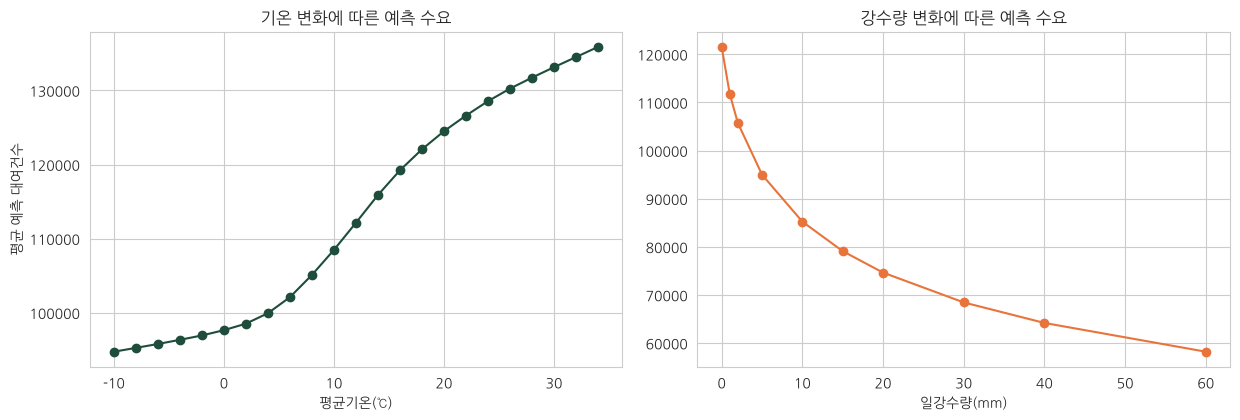

평균기온(℃)       -10.0     -8.0     -6.0     -4.0     -2.0      0.0      2.0      4.0       6.0       8.0      10.0      12.0      14.0      16.0      18.0      20.0      22.0      24.0      26.0      28.0      30.0      32.0      34.0
평균 예측 대여건수  94749.0  95265.0  95792.0  96353.0  96942.0  97654.0  98534.0  99943.0  102109.0  105111.0  108490.0  112153.0  115896.0  119235.0  122060.0  124503.0  126617.0  128560.0  130250.0  131736.0  133143.0  134512.0  135881.0
※ 학습 데이터의 평균기온 범위는 -11.7 ~ 32.8 ℃ 이므로 이 범위를 벗어난 값은 해석하지 않는다.


,시나리오,평균 예측 대여건수,맑은 날 대비(%)
0,강수 1mm,111770.0,-8.0
1,강수 2mm,105752.0,-13.0
2,강수 5mm,95001.0,-21.8
3,강수 10mm,85236.0,-29.9
4,강수 15mm,79112.0,-34.9
5,강수 20mm,74660.0,-38.6
6,강수 30mm,68463.0,-43.7
7,강수 40mm,64199.0,-47.2
8,강수 60mm,58226.0,-52.1


In [18]:
# 테스트 구간 전체 날짜에 대해, 대상일 날씨만 바꿔서 평균 예측 대여량을 계산
raw_te = df.iloc[WINDOW:].iloc[te]            # 테스트 대상일의 원래 날씨
def predict_with(raw_target):
    e_new = ((make_features(raw_target) - x_mean) / x_std).values
    return inv(forward(P, X_seq[te], e_new))

def sweep(var, grid):
    out = []
    for v in grid:
        r = raw_te.copy()
        if var == 'temp':                     # 평균기온을 v로 맞추고 최고·최저는 같은 폭만큼 이동
            d_ = v - r['temp_mean']; r['temp_mean'] = v; r['temp_max'] += d_; r['temp_min'] += d_
        else:
            r[var] = v
        out.append(predict_with(r).mean())
    return np.array(out)

g_temp, g_rain = np.arange(-10, 35, 2), np.array([0, 1, 2, 5, 10, 15, 20, 30, 40, 60])
s_temp, s_rain = sweep('temp', g_temp), sweep('rain', g_rain)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax[0].plot(g_temp, s_temp, marker='o', color=GREEN); ax[0].set_xlabel('평균기온(℃)'); ax[0].set_ylabel('평균 예측 대여건수'); ax[0].set_title('기온 변화에 따른 예측 수요')
ax[1].plot(g_rain, s_rain, marker='o', color=ORANGE); ax[1].set_xlabel('일강수량(mm)'); ax[1].set_title('강수량 변화에 따른 예측 수요')
plt.tight_layout(); save_fig('sens'); plt.show()
print(pd.DataFrame({'평균기온(℃)': g_temp, '평균 예측 대여건수': s_temp.round(0)}).T.to_string(header=False))
print('※ 학습 데이터의 평균기온 범위는', df['temp_mean'].min().round(1), '~', df['temp_mean'].max().round(1), '℃ 이므로 이 범위를 벗어난 값은 해석하지 않는다.')

base_rain = s_rain[0]
imp = pd.DataFrame({'시나리오': [f'강수 {g}mm' for g in g_rain[1:]], '평균 예측 대여건수': s_rain[1:].round(0), '맑은 날 대비(%)': ((s_rain[1:] / base_rain - 1) * 100).round(1)})
imp

## 8. 모델 및 앱용 파일 저장

In [19]:
np.savez('model_weights.npz', **P)
meta = {'window': WINDOW, 'features': FEATURES, 'x_mean': x_mean.tolist(), 'x_std': x_std.tolist(), 'y_mean': float(y_mean), 'y_std': float(y_std),
        'metrics': res.set_index('모델').to_dict('index'), 'data_start': str(df.index.min().date()), 'data_end': str(df.index.max().date()),
        'test_start': str(td[0].date()), 'test_end': str(td[-1].date())}
json.dump(meta, open('meta.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
df.to_csv('daily_dataset.csv')
pd.DataFrame({'date': td, 'actual': y_true, 'lstm': p_lstm}).to_csv('test_pred.csv', index=False)
print('저장 완료 :', ['model_weights.npz', 'meta.json', 'daily_dataset.csv', 'test_pred.csv'])

저장 완료 : ['model_weights.npz', 'meta.json', 'daily_dataset.csv', 'test_pred.csv']
